> **Outputs below predate the 2026-09-08 `build_neuron_model` fix and need a
> re-run.** This notebook used to clamp and record at `dendIDs[-1]`, a direct
> child of the root, because a multi-child root produced electrically isolated
> section trees and the soma's own section was one of them. That is fixed, and
> the readout now sits on the soma. On the same morphology the isolated stub
> fired 12 spikes to a 0.09 nA step where the properly-loaded soma fires 3, so
> every number and figure here will move.

In [1]:
import pynetrees as pt
from pathlib import Path

MORPHOS = Path(r"C:\Users\felix\Documents\neuron_stp\Active GC Model\morphos")


In [2]:
# The Beining et al. 2017 mouse GC population (5 reconstructed cells + axon)
gcs = pt.load_mtr(MORPHOS / "SH_07_all_repairedandsomaAIS_MLyzed.mtr")
for t in gcs:
    print(t)
# Tree(name='03.06_mature_001_contra_007_0v9d_0v9p', n_nodes=3372,
#      regions=[SGCL, GCL, adendIML, adendMML, adendOML, soma, axon, axonh])
# ...

tree = gcs[0]  # a single pynetrees.Tree, plain NumPy underneath


Tree(name='tree1', n_nodes=3765, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree2', n_nodes=4308, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree3', n_nodes=4101, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree4', n_nodes=3641, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree5', n_nodes=3935, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree6', n_nodes=2931, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree7', n_nodes=4022, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])
Tree(name='tree8', n_nodes=3643, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])


In [3]:
import json, numpy as np, pynetrees as pt
from pynetrees.neuron_bridge import build_neuron_model, insert_mechanism

PASSIVE = {"pas", "pasq"}


def build_gc_model(tree, mech_json, celsius=24.0, ek=-90.0, ena=60.0, eca=140.0):
    from neuron import h

    h.celsius = celsius
    mech = json.load(open(mech_json))
    n = tree.n_nodes

    # --- passive: fold every *.pas entry into per-node Ri/Gm/Cm before building ---
    Ri, Gm, Cm = (np.full(n, np.nan) for _ in range(3))

    def fill(p, m):
        Ri[m], Gm[m], Cm[m] = p["Ra"], p["g"], p["cm"]

    if "pas" in mech.get("all", {}):
        fill(mech["all"]["pas"], slice(None))
    for rname in tree.rnames:
        p = mech.get(rname, {}).get("pas")
        if p:
            fill(p, tree.R == tree.rnames.index(rname))
    tree.Ri, tree.Gm, tree.Cm = Ri, Gm, Cm
    e_pas = mech.get("all", {}).get("pas", {}).get("e", -80.0)
    model = build_neuron_model(tree, e_pas=e_pas)

    # --- active mechanisms: "all" first, then region overrides ---
    def apply_params(sec_list, mname, params):
        if not sec_list:
            return
        for sec in sec_list:
            sec.insert(mname)
        probe = getattr(next(iter(sec_list[0])), mname)
        for pname, val in params.items():
            if not np.isscalar(val):
                continue
            val = float(val)
            if hasattr(probe, pname):                     # RANGE -> per segment
                for sec in sec_list:
                    for seg in sec:
                        setattr(getattr(seg, mname), pname, val)
            else:                                         # GLOBAL (or absent)
                try:
                    setattr(h, f"{pname}_{mname}", val)
                except (LookupError, AttributeError):
                    if val != 0.0:
                        print(f"  skip {mname}.{pname}={val:g} — not in compiled .mod")


    for rname in ["all"] + [r for r in mech if r != "all"]:
        for mname, params in mech[rname].items():
            if mname in PASSIVE or mname.endswith("_ion"):
                continue
            if rname == "all":
                sec_list = model.sections
            else:
                sec_list = model.region_sections.get(rname, [])
            apply_params(sec_list, mname, params)

    # --- ion reversals (constant, non-Nernst, as in the MATLAB model) ---
    for sec in model.sections:
        for seg in sec:
            for ion, val in (("ek", ek), ("ena", ena), ("eca", eca)):
                if hasattr(seg, ion):
                    setattr(seg, ion, val)
    return model


In [4]:
tree

Tree(name='tree1', n_nodes=3765, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])

In [5]:

from neuron import h

h.nrn_load_dll(r"C:\Users\felix\Documents\GitHub\PyNeTREES-Toolbox\tests\Active GC Model\lib_mech\nrnmech.dll")
model = build_gc_model(tree, r"C:\Users\felix\Documents\GitHub\PyNeTREES-Toolbox\tests\Active GC Model\gc_mech.json")

In [6]:
import numpy as np

soma_nodes = np.flatnonzero(tree.region_nodes("soma"))
soma_node = int(soma_nodes[soma_nodes.size // 2])


In [7]:
#t, v = pt.run_current_clamp(model, at_node=6, amp=0.09, delay=5, dur=20, tstop=50, v_init=-80)


In [8]:
import matplotlib.pyplot as plt

In [9]:
#plt.plot(t, list(v.values())[0])

# Translation of `GC_dendritic_demo_main_1_6.m`


In [10]:
# ==== §0.2  [tree, neuron, treename] = GC_initModel(ostruct) =====================
# ostruct.vmodel   = 1  -> mechoptions '-a-p-n'   (active model, Beining et al. 2017)
# ostruct.usemorph = 1  -> morphos/SH_07_all_repairedandsomaAIS_MLyzed.mtr  ("SH07all2")
# ostruct.newborn  = 0  -> adult GC ;  scalespines = 1  (folded into gc_mech.json)
GC_ROOT  = Path(r"C:\Users\felix\Documents\GitHub\PyNeTREES-Toolbox\tests\Active GC Model")
MECHJSON = GC_ROOT / "gc_mech.json"                 # dumped from neuron.mech{1} in MATLAB

gc = pt.load_mtr(MORPHOS / "SH_07_all_repairedandsomaAIS_MLyzed.mtr")[0]

# cut the axon at the soma  (GC_initModel.m:269 -- delete the 'axon' region;
# the demo keeps the axon hillock 'axonh'.  Add it to `drop` to remove that too.)
drop = gc.region_nodes("axon")
# drop = gc.region_nodes("axon", "axonh")
gc = pt.delete_tree(gc, drop)
print(f"after axon cut: {gc.n_nodes} nodes, regions {[gc.rnames[r] for r in np.unique(gc.R)]}")

# demo preprocessing loop:  tree{t} = resample_tree(tree{t})   (~1 µm segments;
# this morphology is already MLyzed, so it is close to a no-op — drop if slow)
gc = pt.resample_tree(gc, 10.0)

model  = build_gc_model(gc, MECHJSON, celsius=24.0)  # neuron.params.celsius = 24
V_INIT = -87.3                                       # neuron_main.params.v_init (§2.1)


after axon cut: 2173 nodes, regions ['GCL', 'adendIML', 'adendMML', 'adendOML', 'soma', 'axonh']


In [11]:
# ---- §1  synapse sites: 2nd-longest terminal path, walked back to the soma -------
Tn   = pt.T_tree(gc)                        # termination_nodes{1}   (bool)
plen = pt.Pvec_tree(gc)                     # path_length{1}  [µm]  (metric path length;
                                            # pynetrees PL_tree is *topological* depth, not µm)
slen = pt.len_tree(gc)                      # length_seg{1}          [µm]

# [~, termination_max] = maxk(termination_nodes .* path_length, 2);  dendIDs(1) = (2)
dendID = int(np.argsort(Tn * plen)[::-1][1])

# `path_to_root` replaces the hand-written parent walk this used to do:
#     par = pt.idpar_tree(gc, root_self=False)
#     while par[dendIDs[-1]] > 0: ...
# `> 0` silently drops the root whenever the root is node 0 -- which it is,
# after sort_tree -- so the old version stopped one node short of the soma.
dendIDs = pt.path_to_root(gc, dendID).tolist()

nsyn = np.zeros(gc.n_nodes)                 # binary "synapse present" marker
nsyn[dendIDs] = 1

steps_syns = 1
synids = dendIDs[::steps_syns]
print(f"{len(synids)} synapse nodes along a {plen[dendID]:.0f} µm path "
      f"(tip region: {gc.rnames[gc.R[dendID]]})")


26 synapse nodes along a 243 µm path (tip region: adendOML)


In [12]:

pl = pt.plot_tree(gc, categories=True,scalars=gc.R)

pt.pointer_tree(pl, gc, synids, style="sphere", color="red", size=2.0)
pl.camera_position = "xy"
pl.show()


Widget(value='<iframe src="http://localhost:59876/index.html?ui=P_0x22a929453d0_0&reconnect=auto" class="pyvis…

### §2  Stimulation protocol  (deterministic reduction)

MATLAB places 4 "main" release sites + 10 Poisson-background presynaptic groups, each run
through the stochastic Tsodyks–Markram model (`quantal_TM.m`, per-ROI values for OML vs
MML) feeding `Exp2Synq2` point processes, all inside `t2n_atpMM`.

Below: one shared `phase_locked` train drives a plain `Exp2Syn` at **every** node on the
selected path — same `tau1 = 0.2`, `tau2 = 2.5`, `e = 0`, fixed weight
`syn_ampa = 0.08e-3`. No vesicle pool, no facilitation/depression, no background, no
charge counting.


In [13]:
# ---- phase_locked(): theta-modulated Poisson input train  (reduced port) --------
# MATLAB `phase_locked.m` (Pattern_separation_toolbox) builds spike trains whose
# instantaneous rate is sinusoidally modulated at the theta frequency, so spikes
# cluster around a preferred phase.  Reduced here to a single inhomogeneous-Poisson
# train drawn by thinning:
#     lambda(t) = rate * (1 + amplitude * sin(2*pi * num_phase * t))            [Hz]
# Args in SECONDS; returns spike times in SECONDS, sorted.  No per-trial loop and
# no jitter kernel — just enough drive for the Exp2Syn sites below.
def phase_locked(duration_s, rate=5.0, amplitude=0.7, num_phase=6.0, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    lam_max = rate * (1.0 + abs(amplitude))
    cand = np.sort(rng.uniform(0.0, duration_s, size=rng.poisson(lam_max * duration_s)))
    lam = rate * (1.0 + amplitude * np.sin(2.0 * np.pi * num_phase * cand))
    return cand[rng.uniform(0.0, lam_max, size=cand.size) < lam]


In [14]:
# ---- §2  stimulation (single unitary pulse per synapse) ------------------------
from neuron import h
h.load_file("stdrun.hoc")

TSTOP  = 5000.0        # neuron_main.params.tstop  (§3 — trim this now that it's one pulse)
DT     = 2            # neuron_main.params.dt     (§2.1)
PRERUN = 100.0         # neuron_main.params.prerun (§2.1)
SYN_W  = 0.08e-3       # syn_ampa = 0.08*10^-3     (§0.3)
STIM_T = PRERUN + 20.0 # one event, 20 ms after the prerun has settled

# one shared NetStim emits exactly one spike -> every site on the path fires once,
# synchronously.  MATLAB instead runs each site through quantal_TM.m + an Exp2Synq2
# point process; here each site is a plain unitary Exp2Syn activation (as in §2.3).
stim = h.NetStim()
stim.number   = 1
stim.start    = STIM_T
stim.noise    = 0.0
stim.interval = 1.0        # unused with number == 1

syns, netcons = [], []
for nid in synids:
    s = h.Exp2Syn(model.loc(int(nid)))
    s.tau1, s.tau2, s.e = 0.2, 2.5, 0.0         # Exp2Synq2 kinetics (DGGC_prepare_for_t2n)
    nc = h.NetCon(stim, s)
    nc.weight[0] = SYN_W
    nc.delay = 0.0
    syns.append(s)
    netcons.append(nc)

print(f"{len(synids)} Exp2Syn sites, one pulse each at t={STIM_T - PRERUN:.0f} ms after onset")


26 Exp2Syn sites, one pulse each at t=20 ms after onset


### §2.3  Democratization  (`GC_dendritic_demo_main_2.mlx`)

The point of the script.  `_2` builds a **base neuron** — an `Exp2Synq2` at every
node of the synapse path, each fired once by its own `NetStim` staggered
`step_t = 100` ms apart (`start = 50 + 100·k`) — and voltage-clamps the soma
(`des_volt = -88.5805`, `rs = 20`).  `findpeaks` on the clamp current gives

```
I_peaks(k) = peak somatic EPSC from a unitary activation of path site k
```

ordered **distal → proximal** (`synids(1) = dendIDs(1)` = the 2nd-longest
terminal tip).  `_2` scales weights to the **first** site, `I_peaks(1)` (the
distal tip — `_1_6` normalised to the proximal site instead), and compares two
profiles against the uniform original:

| variant | rule | MATLAB |
|---|---|---|
| Region Regression | `w(n) = A · I_peaks(1) / f_region(dist(n))` | `neuronn{2}` |
| Inverse Norm | `w(n) = A · I_peaks(1) / I_peaks(n)` | `neuronn{3}` |

`f_region` is a per-region `poly2` fit of `I_peaks` vs path distance, over the
dendritic layers (`GCL / adendIML / adendMML / adendOML`) only; soma / axon-hillock
sites keep the uniform weight `A`.  `I_peaks` is measured directly here — one
unitary `Exp2Syn` activation per site with the soma voltage-clamped — then the
`netcons` weights from §2 are overwritten.  Run **after** §2 and **before** §3;
the run itself uses the Inverse-Norm profile (as in `_2`'s Main-Script §2.3).


In [15]:
# ==== §2.3  Democratization  (port of GC_dendritic_demo_main_2.mlx, §1) =========
# _2 builds a "base neuron" with an Exp2Synq2 at every path node, each driven by
# its own NetStim staggered `step_t = 100` ms apart (start = 50 + 100*k), with the
# soma held under SEClamp (des_volt = -88.5805, rs = 20).  findpeaks on the clamp
# current then gives I_peaks[k] = the unitary somatic EPSC of path site k, ordered
# distal -> proximal (synids[0] = dendIDs[0] = the 2nd-longest terminal tip).
#
# Reproduced here one site at a time (isolated sim, near-ideal clamp) -- same
# quantity, no findpeaks index-alignment to worry about.  ~len(synids) short sims.
from neuron import h
h.load_file("stdrun.hoc")

VHOLD_DEMO = -88.5805        # _2: des_volt for the reference SEClamp (§1.1)

# `build_neuron_model` used to leave the root's section electrically detached
# from the dendrites when the root had several children, which forced this to
# clamp at dendIDs[-1] (a direct child of the root) instead. Fixed 2026-09-08:
# the trunks are now joined at their own 0 ends, so the soma itself is the
# right place to clamp and record.
soma_node = int(np.flatnonzero(gc.region_nodes("soma"))[0])

def unitary_somatic_epsc(syn_node, soma_node, *, mdl=None, w=SYN_W, vhold=VHOLD_DEMO,
                         tau1=0.2, tau2=2.5, prerun=150.0, win=40.0,
                         dt_settle=1.0, dt_meas=0.1):
    """Peak of |I_SEClamp - baseline| for one unitary EPSC [nA]  (on `mdl`, default `model`).

    Settle under the clamp for `prerun` ms first (== _2's neuron.params.prerun) so
    the measurement starts from steady state -- without it the clamp is still
    relaxing the whole cell off finitialize(vhold), and that ~syn_node-independent
    settling transient swamps the EPSC and flattens I_peaks across sites.  The
    settle runs at `dt_settle` (pure relaxation, coarse is fine); only the EPSC
    window runs at `dt_meas` -- backward-Euler damps fast transients, so a coarse
    step there would clip the sharp near-soma peaks and squash the distal->proximal
    ratio the democratization weights are built from.  Baseline is the 5 ms before
    the release; the peak is searched only in `win` ms after it.
    """
    mdl = model if mdl is None else mdl
    syn = h.Exp2Syn(mdl.loc(int(syn_node)))
    syn.tau1, syn.tau2, syn.e = tau1, tau2, 0.0
    t_stim = prerun + 5.0
    ns = h.NetStim(); ns.number = 1; ns.noise = 0.0; ns.start = t_stim
    nc = h.NetCon(ns, syn); nc.weight[0] = w; nc.delay = 0.0
    cl = h.SEClamp(mdl.loc(int(soma_node)))
    cl.rs = 0.01; cl.dur1 = 1e9; cl.amp1 = vhold        # near-ideal clamp (_2 uses rs=20)
    ti = h.Vector().record(h._ref_t)
    ii = h.Vector().record(cl._ref_i)
    h.cvode_active(0); h.celsius = 24.0
    h.dt = dt_settle
    h.finitialize(vhold)
    h.continuerun(prerun)                                # coarse settle
    h.dt = dt_meas
    h.continuerun(t_stim + win)                          # fine over the EPSC
    ti, ii = np.array(ti), np.array(ii)
    base = ii[(ti >= t_stim - 5.0) & (ti < t_stim)].mean()
    peak = float(np.max(np.abs(ii[ti >= t_stim] - base)))
    del syn, ns, nc, cl, ti, ii                          # drop point processes off the model
    return peak

I_peaks = np.array([unitary_somatic_epsc(nid, soma_node) for nid in synids])
dist    = np.array([plen[int(nid)] for nid in synids])
print(f"{len(synids)} sites | I_peaks {I_peaks.min()*1e3:.2f}-{I_peaks.max()*1e3:.2f} pA "
      f"(x{I_peaks.max()/max(I_peaks.min(),1e-12):.1f} distal->proximal) "
      f"| dist {dist.min():.0f}-{dist.max():.0f} µm | ref = I_peaks[0] (distal tip)")


26 sites | I_peaks 2.01-7.03 pA (x3.5 distal->proximal) | dist 10-243 µm | ref = I_peaks[0] (distal tip)


In [16]:
I_peaks


array([0.00200882, 0.00201154, 0.00201886, 0.00202832, 0.00204096,
       0.0020574 , 0.00207753, 0.00210232, 0.00211773, 0.00213299,
       0.00216981, 0.00224554, 0.00230698, 0.00247834, 0.00271133,
       0.00295161, 0.00339853, 0.00368692, 0.00388888, 0.004086  ,
       0.00432812, 0.00445866, 0.00484103, 0.00531514, 0.00616837,
       0.00702636])

applied inverse-norm: weight x0.29 .. x1.00  (26/26 dendritic sites rescaled; fits: ['GCL', 'adendIML', 'adendMML', 'adendOML'])


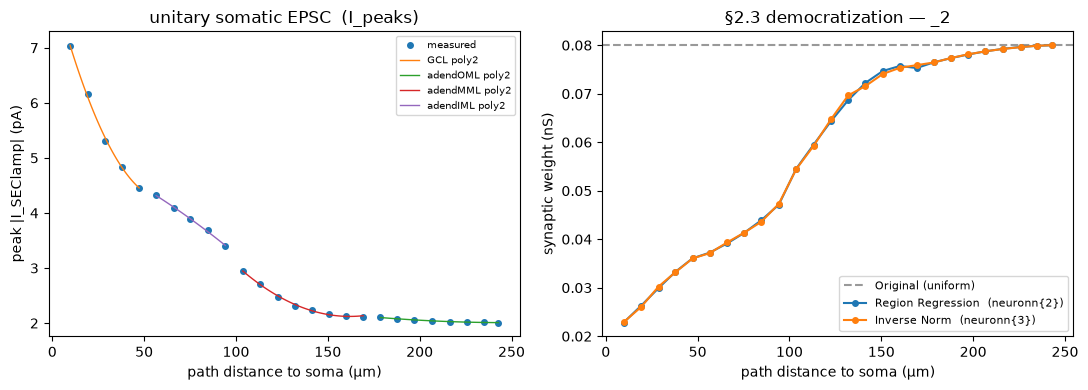

In [17]:
# ---- §2.3  two democratized weight profiles  (port of _2 §1) -------------------
# reference = I_peaks[0]  (MATLAB data.I_peaks{1,1}(1) -- the FIRST synid, i.e. the
# distal tip; _1_6 normalised to the proximal site instead).  Only dendritic-layer
# sites are rescaled; soma / axon-hillock sites keep the uniform weight A.
#
#   w_region[n] = A * I_peaks[0] / poly2_region(dist[n])   (neuronn{2})
#   w_inv[n]    = A * I_peaks[0] / I_peaks[n]              (neuronn{3})
import numpy as np
import matplotlib.pyplot as plt

A      = SYN_W
ref    = 0                                           # _2: data.I_peaks{1,1}(1)
DEND_R = {"GCL", "adendIML", "adendMML", "adendOML"}

reg_name = np.array([gc.rnames[int(gc.R[int(nid)])] for nid in synids])
is_dend  = np.array([r in DEND_R for r in reg_name])

# neuronn{3}: inverse normalization -------------------------------------------
w_inv = A * I_peaks[ref] / np.clip(I_peaks, 1e-12, None)

# neuronn{2}: per-region poly2 regression ------------------------------------
# quadratic fit of I_peaks vs path distance within each dendritic region that has
# >2 sites (MATLAB `if length(dist_idx) > 2`); regions with fewer points fall back
# to the measured value there (== w_inv for those sites).
region_fit = {}
for r in DEND_R:
    m = reg_name == r
    if m.sum() > 2:
        region_fit[r] = np.polyfit(dist[m], I_peaks[m], 2)

pred = I_peaks.astype(float).copy()
for i, r in enumerate(reg_name):
    if r in region_fit:
        pred[i] = np.polyval(region_fit[r], dist[i])
w_region = A * I_peaks[ref] / np.clip(pred, 1e-12, None)

# non-dendritic sites keep the uniform weight (MATLAB `if syn_type < 5`)
w_inv[~is_dend]    = A
w_region[~is_dend] = A

# apply one profile to the run.  _2's Main-Script §2.3 uses the inverse-norm form;
# set `w_demo = w_region` for the neuronn{2} variant instead.
w_demo = w_inv
for nc, w in zip(netcons, w_demo):
    nc.weight[0] = float(w)
print(f"applied inverse-norm: weight x{w_demo.min()/A:.2f} .. x{w_demo.max()/A:.2f}  "
      f"({int(is_dend.sum())}/{len(synids)} dendritic sites rescaled; "
      f"fits: {sorted(region_fit) or 'none (too few sites/region)'})")

# comparative plot  (Original / Region Regression / Inverse Norm) --------------
order = np.argsort(dist)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(dist, I_peaks * 1e3, "o", ms=4, label="measured")
for r, c in region_fit.items():
    xs = np.linspace(dist[reg_name == r].min(), dist[reg_name == r].max(), 40)
    ax[0].plot(xs, np.polyval(c, xs) * 1e3, "-", lw=1, label=f"{r} poly2")
ax[0].set_xlabel("path distance to soma (µm)")
ax[0].set_ylabel("peak |I_SEClamp| (pA)")
ax[0].set_title("unitary somatic EPSC  (I_peaks)")
ax[0].legend(fontsize=7)

ax[1].axhline(A * 1e3, ls="--", c="0.6", label="Original (uniform)")
ax[1].plot(dist[order], w_region[order] * 1e3, "-o", ms=4, label="Region Regression  (neuronn{2})")
ax[1].plot(dist[order], w_inv[order] * 1e3, "-o", ms=4, label="Inverse Norm  (neuronn{3})")
ax[1].set_xlabel("path distance to soma (µm)")
ax[1].set_ylabel("synaptic weight (nS)")
ax[1].set_title("§2.3 democratization — _2")
ax[1].legend(fontsize=8)
plt.tight_layout()


passive: I_peaks 2.26-7.07 pA (x3.1)  |  active x3.5


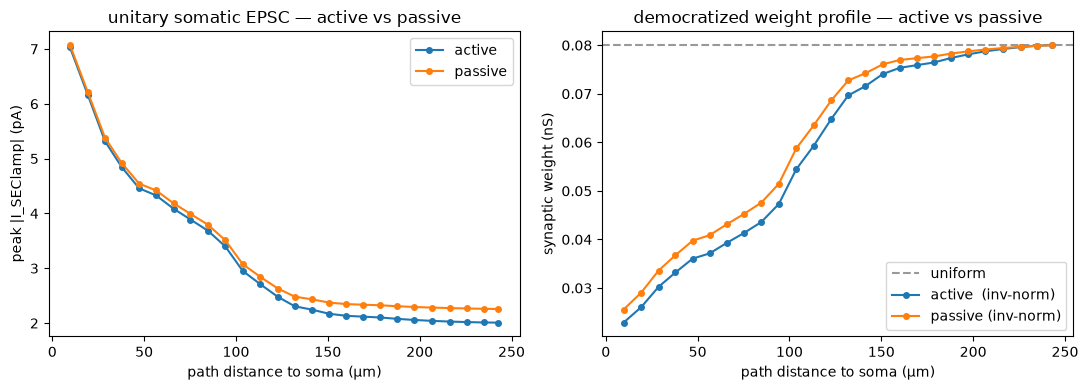

In [18]:
# ---- §2.3 (aside)  same sweep on a PASSIVE-only cell  (_2 ostruct.vmodel = 0) --
# Rebuild the morphology with the leak folded in but no active channels and repeat
# the unitary-EPSC sweep.  Pure cable: how much of the distal->proximal I_peaks
# falloff is geometry + leak, vs shaped by the active conductances.
# (gc already carries .Ri/.Gm/.Cm from the build_gc_model call in §0.2.)
e_pas_val = json.load(open(MECHJSON)).get("all", {}).get("pas", {}).get("e", -80.0)
model_pas = build_neuron_model(gc, e_pas=e_pas_val)   # separate, unconnected section
                                                     # tree -> no cross-talk with `model`

I_peaks_pas = np.array([unitary_somatic_epsc(nid, soma_node, mdl=model_pas) for nid in synids])
w_inv_pas   = A * I_peaks_pas[ref] / np.clip(I_peaks_pas, 1e-12, None)
w_inv_pas[~is_dend] = A
print(f"passive: I_peaks {I_peaks_pas.min()*1e3:.2f}-{I_peaks_pas.max()*1e3:.2f} pA "
      f"(x{I_peaks_pas.max()/max(I_peaks_pas.min(),1e-12):.1f})  |  "
      f"active x{I_peaks.max()/max(I_peaks.min(),1e-12):.1f}")

order = np.argsort(dist)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(dist[order], I_peaks[order]     * 1e3, "-o", ms=4, label="active")
ax[0].plot(dist[order], I_peaks_pas[order] * 1e3, "-o", ms=4, label="passive")
ax[0].set_xlabel("path distance to soma (µm)")
ax[0].set_ylabel("peak |I_SEClamp| (pA)")
ax[0].set_title("unitary somatic EPSC — active vs passive")
ax[0].legend()
ax[1].axhline(A * 1e3, ls="--", c="0.6", label="uniform")
ax[1].plot(dist[order], w_inv[order]     * 1e3, "-o", ms=4, label="active  (inv-norm)")
ax[1].plot(dist[order], w_inv_pas[order] * 1e3, "-o", ms=4, label="passive (inv-norm)")
ax[1].set_xlabel("path distance to soma (µm)")
ax[1].set_ylabel("synaptic weight (nS)")
ax[1].set_title("democratized weight profile — active vs passive")
ax[1].legend()
plt.tight_layout()


In [19]:
# ---- §3  run:  prerun to steady state, then the stimulus window -----------------
soma_node = int(np.flatnonzero(gc.region_nodes("soma"))[0])      # same soma readout as §2.3

t_vec  = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(model.loc(soma_node)._ref_v)
v_dend = h.Vector().record(model.loc(int(dendID))._ref_v)

h.cvode_active(0)
h.dt = DT                                        # neuron_main.params.dt = 0.5
h.celsius = 24.0
h.finitialize(V_INIT)
h.continuerun(PRERUN + TSTOP)                    # prerun then stimulus, one shot

t      = np.array(t_vec) - PRERUN               # t = 0 at stimulus onset
v_soma = np.array(v_soma)
v_dend = np.array(v_dend)
print(f"tstop={TSTOP} ms  dt={h.dt} ms  samples={t.size}  V_soma rest≈{v_soma[t >= 0][0]:.1f} mV")


tstop=5000.0 ms  dt=2.0 ms  samples=2551  V_soma rest≈-86.6 mV


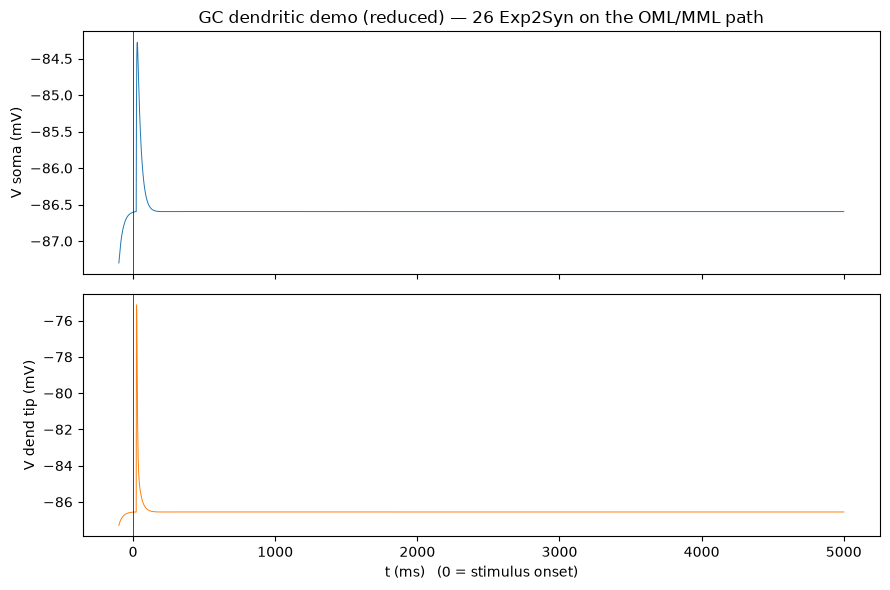

In [20]:
# ---- §4  plot somatic & dendritic-tip voltage ------------------------------------
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, v_soma, lw=0.7)
ax[0].set_ylabel("V soma (mV)")
ax[0].set_title(f"GC dendritic demo (reduced) — {len(synids)} Exp2Syn on the OML/MML path")
ax[1].plot(t, v_dend, lw=0.7, color="C1")
ax[1].set_ylabel("V dend tip (mV)")
ax[1].set_xlabel("t (ms)   (0 = stimulus onset)")
for a in ax:
    a.axvline(0.0, color="k", lw=0.5)
plt.tight_layout()
